**Generación de funciones de densidad de probabilidad mediante el uso de Google
Colab y Python** - Grupo 3



- **VARIABLE ALEATORIA 1**:  Intervalo entre arribos de trámites complejos (en minutos).
- **VARIABLE ALEATORIA 2**:  Intervalo entre arribos de trámites simples (en minutos).
- **VARIABLE ALEATORIA 3**:  Tiempo de resolución de un trámite complejo (en minutos).
- **VARIABLE ALEATORIA 4**:  Tiempo de resolución de un trámite simple (en minutos).

**1. Carga de bibliotecas**

In [ ]:
pip install fitter

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.3/80.3 kB 2.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 3.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.6/61.6 kB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 19.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.7/16.7 MB 42.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 41.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 71.9/71.9 kB 2.3 MB/s eta 0:00:00
  Attempting uninstall: numpy
    Found existing installation: numpy 2.1.3
    Uninstalling numpy-2.1.3:
      Successfully uninstalled numpy-2.1.3
  Attempting uninstall: pandas
    Found existing installation: pandas 2.2.3
    Uninstalling pandas-2.2.3:
      Successfully uninstalled pandas-2.2.3
  Attempting uninstall: matplotlib
    Found existing installation: matplotlib 3.10.0
    Uninstalling matplotlib-3.10.0:
      Successfully uninstal

In [ ]:
from fitter import Fitter
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import glob

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


**2.1 - IA - Carga de datos**

In [ ]:
ruta = '/content/drive/MyDrive/TP5 - Simul./Datasets/habilitacionesSimplesYEspeciales.csv'

tramitesDF = pd.read_csv(ruta, encoding='latin-1', sep=';')

tramitesDF.head()


,Solicitud,TipoTramite,TipoExpediente,SubTipoExpediente,Superficie,FechaHabilitacion,HoraHabilitacion,NumeroExp,CodigoRubro,DescripcionRubro,...,DescripcionSubRubro,UnidadFuncional,Seccion,Manzana,Parcela,Partida_Matriz,PartidaHorizontal,Calles,Titulares,Cuits
0,348374,Habilitación,simple,con planos,600,14/11/2024,17:25:29,EX-2017-21751300- -MGEYA-DGHP,602020,CAFÉ BAR,...,NaN,NaN,35,63,7,404886,NaN,NICARAGUA 6048,ORLANDO BRENNAN MARIA LUZ TRINCAVELLI AGUSTINA,30715644130
1,348374,Habilitación,simple,con planos,600,14/11/2024,17:25:29,EX-2017-21751300- -MGEYA-DGHP,602030,"DESPACHO DE BEBIDAS,WISQUERIA, CERVECERIA",...,NaN,NaN,35,63,7,404886,NaN,NICARAGUA 6048,ORLANDO BRENNAN MARIA LUZ TRINCAVELLI AGUSTINA,30715644130
2,417920,Habilitación,simple,con planos,280,19/12/2024,13:52:22,EX-2024-47690876- -GCABA-DGHP,2.1.1,Espacio cultural independiente,...,NaN,1,67,80,40,248761,2803829,"ARTIGAS, JOSE GERVASIO, GRAL. 1850","GUTIERREZ, DIEGO FEDERICO",20268445642
3,418987,Habilitación,simple,con planos,148,29/11/2024,16:05:28,EX-2024-45093670- -GCABA-DGHP,5.2.2,Consultorio profesional,...,NaN,8,15,26,1,444521,3553170,BERUTI 3208,SALUD Y DEPORTES S.R.L.,30716542056
4,428918,Habilitación,simple,con planos,149,27/12/2024,14:36:30,EX-2024-42014526- -GCABA-DGHP,1.8,Comercio minorista excluido comestibles como u...,...,COMERCIO MINORISTA VENTA DE ARTICULOS PARA ANI...,NaN,81,55,8,308577,NaN,CHIVILCOY 2299;SANTO TOME 4090,SERVICIOS INTEGRALES VETERINARIOS S.R.L.,30716809761


**3.1 - IA - Análisis Exploratorio de Datos**

In [ ]:
tramitesDF = tramitesDF[['Solicitud', 'FechaHabilitacion', 'HoraHabilitacion', 'TipoTramite', 'TipoExpediente']]
tramitesDF.head()

,Solicitud,FechaHabilitacion,HoraHabilitacion,TipoTramite,TipoExpediente
0,348374,14/11/2024,17:25:29,Habilitación,simple
1,348374,14/11/2024,17:25:29,Habilitación,simple
2,417920,19/12/2024,13:52:22,Habilitación,simple
3,418987,29/11/2024,16:05:28,Habilitación,simple
4,428918,27/12/2024,14:36:30,Habilitación,simple


In [ ]:
# Parseos

tramitesDF['FechaHabilitacion'] = pd.to_datetime(tramitesDF['FechaHabilitacion'], format='%d/%m/%Y')
tramitesDF['HoraHabilitacion'] = pd.to_datetime(tramitesDF['HoraHabilitacion'], format='%H:%M:%S').dt.time
tramitesDF.dtypes
tramitesDF.head()

,Solicitud,FechaHabilitacion,HoraHabilitacion,TipoTramite,TipoExpediente
0,348374,2024-11-14,17:25:29,Habilitación,simple
1,348374,2024-11-14,17:25:29,Habilitación,simple
2,417920,2024-12-19,13:52:22,Habilitación,simple
3,418987,2024-11-29,16:05:28,Habilitación,simple
4,428918,2024-12-27,14:36:30,Habilitación,simple


In [ ]:
# Ordenar por fecha

tramitesDF = tramitesDF.sort_values('FechaHabilitacion')
tramitesDF.head()

,Solicitud,FechaHabilitacion,HoraHabilitacion,TipoTramite,TipoExpediente
3635,511568,2024-10-01,16:34:42,Habilitación,simple
1465,503332,2024-10-01,00:16:47,Habilitación,simple
1464,503332,2024-10-01,00:16:47,Habilitación,simple
1463,503332,2024-10-01,00:16:47,Habilitación,simple
1462,503332,2024-10-01,00:16:47,Habilitación,simple


In [ ]:
# División de dataframes por simple y complejo (o especial)

tramitesDFSimple = tramitesDF[tramitesDF['TipoExpediente'] == 'simple'].reset_index(drop=True)
tramitesDFComplejo = tramitesDF[tramitesDF['TipoExpediente'] == 'especial'].reset_index(drop=True)

tramitesDFSimple = tramitesDFSimple.drop_duplicates(subset='Solicitud').reset_index(drop=True)
tramitesDFComplejo = tramitesDFComplejo.drop_duplicates(subset='Solicitud').reset_index(drop=True)

tramitesDFSimple['HoraHabilitacion'] = pd.to_timedelta(tramitesDFSimple['HoraHabilitacion'].astype(str))
tramitesDFComplejo['HoraHabilitacion'] = pd.to_timedelta(tramitesDFComplejo['HoraHabilitacion'].astype(str))


**4. Preparación de datos**

In [ ]:
# Calcular intervalos por día

def calcular_intervalos_por_dia_con_jitter(df, jitter_max_seg=30, seed=42):
    rng = np.random.default_rng(seed)
    intervalos = []
    for fecha, grupo in df.groupby('FechaHabilitacion'):
        grupo_ordenado = grupo.sort_values('HoraHabilitacion').copy()
        jitter = pd.to_timedelta(rng.uniform(0, jitter_max_seg, size=len(grupo_ordenado)), unit='s')
        grupo_ordenado['HoraJitter'] = grupo_ordenado['HoraHabilitacion'] + jitter
        grupo_ordenado = grupo_ordenado.sort_values('HoraJitter')
        diffs = grupo_ordenado['HoraJitter'].diff().dt.total_seconds() / 60
        intervalos.extend(diffs.dropna().tolist())
    return pd.Series(intervalos)

intervalos_simple = calcular_intervalos_por_dia_con_jitter(tramitesDFSimple, jitter_max_seg=30)
intervalos_complejo = calcular_intervalos_por_dia_con_jitter(tramitesDFComplejo, jitter_max_seg=30)


# Filtrar ceros y negativos

intervalos_simple = intervalos_simple[intervalos_simple > 0].reset_index(drop=True)
intervalos_complejo = intervalos_complejo[intervalos_complejo > 0].reset_index(drop=True)


distribuciones_simple = ['gamma', 'weibull_min', 'lognorm', 'rayleigh', 'invgamma']
distribuciones_complejo = ['gamma', 'weibull_min', 'lognorm', 'rayleigh', 'invgamma']

def sse_contra_histograma(datos, nombre_dist, params, bins=60, rango=None):
    rango = rango if rango else (0, datos.max())
    y_hist, bin_edges = np.histogram(datos, bins=bins, range=rango, density=True)
    x_centros = (bin_edges[:-1] + bin_edges[1:]) / 2
    dist = getattr(stats, nombre_dist)
    y_pred = dist.pdf(x_centros, *params)
    return np.sum((y_hist - y_pred) ** 2)

def elegir_mejor_distribucion(datos, candidatas, bins=60, rango=None):
    resultados = {}
    for nombre in candidatas:
        try:
            dist = getattr(stats, nombre)
            params = dist.fit(datos, floc=0)
            sse = sse_contra_histograma(datos, nombre, params, bins=bins, rango=rango)
            resultados[nombre] = {'params': params, 'sse': sse}
        except Exception as e:
            print(f"  {nombre}: no se pudo ajustar ({e})")
    mejor_nombre = min(resultados, key=lambda k: resultados[k]['sse'])
    return mejor_nombre, resultados

mejor_simple, res_simple = elegir_mejor_distribucion(intervalos_simple, distribuciones_simple, bins=60, rango=(0, 20))

mejor_complejo, res_complejo = elegir_mejor_distribucion(intervalos_complejo, distribuciones_complejo, bins=60, rango=(0, 100))


resultados_por_tipo = {
    'Simple': {
        'distribucion': mejor_simple,
        'params': res_simple[mejor_simple]['params'],
        'media': intervalos_simple.mean(),
        'varianza': intervalos_simple.var(),
        'n_obs': len(intervalos_simple)
    },
    'Complejo': {
        'distribucion': mejor_complejo,
        'params': res_complejo[mejor_complejo]['params'],
        'media': intervalos_complejo.mean(),
        'varianza': intervalos_complejo.var(),
        'n_obs': len(intervalos_complejo)
    }
}




In [ ]:
# Funciones generadoras

max_simple = np.percentile(intervalos_simple, 99)
max_complejo = np.percentile(intervalos_complejo, 99)

def _generar_valor(nombre_dist, params, minimo, maximo):
    dist = getattr(stats, nombre_dist)
    valor = dist.rvs(*params)
    intentos = 0
    while valor <= minimo or valor > maximo:
        valor = dist.rvs(*params)
        intentos += 1
        if intentos > 1000:
            valor = minimo + 1e-3
            break
    return valor

def generar_intervalo_simple(minimo=0.1, maximo=max_simple):
    info = resultados_por_tipo['Simple']
    return _generar_valor(info['distribucion'], info['params'], minimo, maximo)

def generar_intervalo_complejo(minimo=0.1, maximo=max_complejo):
    info = resultados_por_tipo['Complejo']
    return _generar_valor(info['distribucion'], info['params'], minimo, maximo)

muestras_simple = [generar_intervalo_simple() for _ in range(100000)]
muestras_complejo = [generar_intervalo_complejo() for _ in range(100000)]

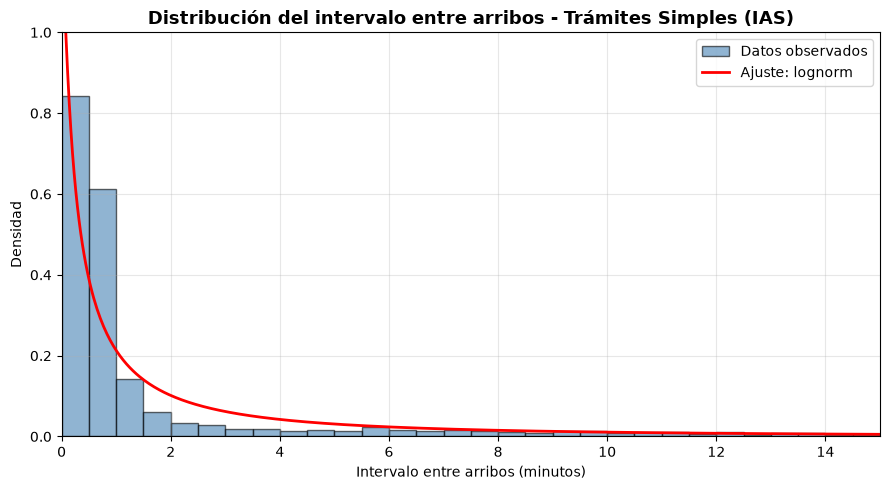

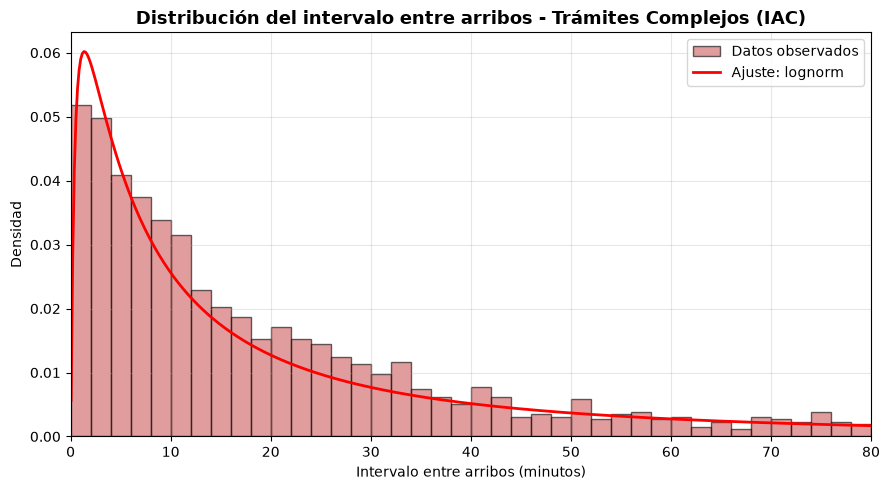

In [ ]:
# Gráficos

def graficar_distribucion(datos, info, titulo, color='steelblue', xlim=None, ylim=None, bins=40, x_min_curva=0.05):
    plt.figure(figsize=(9, 5))
    rango_hist = xlim if xlim else (0, datos.max())
    plt.hist(datos, bins=bins, range=rango_hist, density=True, alpha=0.6,
              color=color, edgecolor='black', label='Datos observados')

    nombre_dist = info['distribucion']
    params = info['params']
    dist = getattr(stats, nombre_dist)

    x_max = xlim[1] if xlim else datos.max()
    x = np.linspace(x_min_curva, x_max, 500)
    y = dist.pdf(x, *params)

    plt.plot(x, y, 'r-', linewidth=2, label=f'Ajuste: {nombre_dist}')
    plt.title(titulo, fontsize=13, fontweight='bold')
    plt.xlabel('Intervalo entre arribos (minutos)')
    plt.ylabel('Densidad')
    if xlim:
        plt.xlim(xlim)
    if ylim:
        plt.ylim(ylim)
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

graficar_distribucion(
    intervalos_simple, resultados_por_tipo['Simple'],
    'Distribución del intervalo entre arribos - Trámites Simples (IAS)',
    color='steelblue', xlim=(0, 15), ylim=(0, 1), bins=30
)

graficar_distribucion(
    intervalos_complejo, resultados_por_tipo['Complejo'],
    'Distribución del intervalo entre arribos - Trámites Complejos (IAC)',
    color='indianred', xlim=(0, 80)
)

In [ ]:
# Funciones generadoras
print("Simulando 10 próximos arribos de trámites simples:")
for i in range(10):
    print(f"  {i+1}. {generar_intervalo_simple():.2f} min")

print("\nSimulando 10 próximos arribos de trámites complejos:")
for i in range(10):
    print(f"  {i+1}. {generar_intervalo_complejo():.2f} min")

Simulando 10 próximos arribos de trámites simples:
  1. 0.61 min
  2. 0.18 min
  3. 1.16 min
  4. 0.19 min
  5. 7.92 min
  6. 1.34 min
  7. 1.19 min
  8. 5.01 min
  9. 4.85 min
  10. 0.42 min

Simulando 10 próximos arribos de trámites complejos:
  1. 2.11 min
  2. 3.81 min
  3. 252.02 min
  4. 5.71 min
  5. 142.33 min
  6. 46.59 min
  7. 28.72 min
  8. 8.27 min
  9. 1.26 min
  10. 10.03 min


**PRUEBAS**

**2.2 - TA - Carga de datos**

In [ ]:
rutaNuevoDF = '/content/drive/MyDrive/TP5 - Simul./Datasets/atencion_mesa_entradas_2024_dataset.csv'

mesaEntradasDF = pd.read_csv(rutaNuevoDF,encoding='utf-8', sep=',')

mesaEntradasDF.head()

,id_turno,fecha,hora,dia_semana,categoria,nro_turno,prioridad,estado,estado_desc,espera_minutos,atencion_minutos,puesto
0,54313,2024-01-25,13:05:12,Jueves,Mesa De Entradas,1,0,5,Derivado,9.0,1.0,DESKTOP-KO9BH1L
1,54314,2024-01-25,13:16:25,Jueves,Reclamos,1,0,1,Llamado,0.0,NaN,DESKTOP-KO9BH1L
2,54315,2024-03-20,09:10:52,Miércoles,Atención Ciudadana,1,0,0,Pendiente,NaN,NaN,NaN
3,54316,2024-03-20,09:54:53,Miércoles,Reclamos,1,0,0,Pendiente,NaN,NaN,NaN
4,54317,2024-03-20,10:11:16,Miércoles,Obras Públicas,1,0,0,Pendiente,NaN,NaN,NaN


**3.2 - TA - Análisis Exploratorio de Datos**

In [ ]:
mesaEntradasDF = mesaEntradasDF[mesaEntradasDF['atencion_minutos'].notna()].reset_index(drop=True)
mesaEntradasDF = mesaEntradasDF[['id_turno', 'dia_semana', 'fecha', 'hora', 'categoria', 'atencion_minutos']]
mesaEntradasDF['atencion_minutos'] = mesaEntradasDF['atencion_minutos'].astype(int)
mesaEntradasDF = mesaEntradasDF.sort_values('atencion_minutos', ascending=False).reset_index(drop=True)

print(mesaEntradasDF['categoria'].value_counts())

categoria
Atención Ciudadana    5134
Mesa De Entradas      1294
Obras Privadas        1206
Catastro               969
Caja                   346
Reclamos               235
Audiencias              65
Otros Trámites          30
Obras Públicas           1
Name: count, dtype: int64


In [ ]:
tramitesSimplesDF = mesaEntradasDF[mesaEntradasDF['categoria'] == 'Atención Ciudadana'].reset_index(drop=True)

tramitesComplejosDF = mesaEntradasDF[mesaEntradasDF['categoria'] != 'Atención Ciudadana'].reset_index(drop=True)

tramitesSimplesDF.head()


,id_turno,dia_semana,fecha,hora,categoria,atencion_minutos
0,62629,Martes,2024-10-22,11:04:17,Atención Ciudadana,90
1,64363,Martes,2024-12-17,10:48:22,Atención Ciudadana,63
2,59207,Miércoles,2024-06-26,10:24:52,Atención Ciudadana,62
3,55378,Jueves,2024-04-04,09:08:14,Atención Ciudadana,61
4,57010,Lunes,2024-05-06,10:49:20,Atención Ciudadana,57


**4.2 - TA - Preparación de datos**

In [ ]:
atencion_simple = tramitesSimplesDF['atencion_minutos']
atencion_simple = atencion_simple[atencion_simple > 0].reset_index(drop=True)

atencion_compleja = tramitesComplejosDF['atencion_minutos']
atencion_compleja = atencion_compleja[atencion_compleja > 0].reset_index(drop=True)


rng = np.random.default_rng(42)

atencion_simple_jit = atencion_simple + rng.uniform(0, 1, size=len(atencion_simple))
atencion_compleja_jit = atencion_compleja + rng.uniform(0, 1, size=len(atencion_compleja))


distribuciones_servicio = ['gamma', 'weibull_min', 'lognorm', 'rayleigh', 'invgamma']

def sse_contra_histograma(datos, nombre_dist, params, bins=50, rango=None):
    rango = rango if rango else (0, datos.max())
    y_hist, bin_edges = np.histogram(datos, bins=bins, range=rango, density=True)
    x_centros = (bin_edges[:-1] + bin_edges[1:]) / 2
    dist = getattr(stats, nombre_dist)
    y_pred = dist.pdf(x_centros, *params)
    return np.sum((y_hist - y_pred) ** 2)

def elegir_mejor_distribucion(datos, candidatas, bins=50, rango=None):
    resultados = {}
    for nombre in candidatas:
        try:
            dist = getattr(stats, nombre)
            params = dist.fit(datos, floc=0)
            sse = sse_contra_histograma(datos, nombre, params, bins=bins, rango=rango)
            resultados[nombre] = {'params': params, 'sse': sse}
        except Exception as e:
            print(f"  {nombre}: no se pudo ajustar ({e})")
    mejor_nombre = min(resultados, key=lambda k: resultados[k]['sse'])
    return mejor_nombre, resultados


mejor_simple, res_simple = elegir_mejor_distribucion(atencion_simple_jit, distribuciones_servicio, bins=50, rango=(0, 30))

mejor_complejo, res_complejo = elegir_mejor_distribucion(atencion_compleja_jit, distribuciones_servicio, bins=50, rango=(0, 60))


resultados_servicio = {
    'Simple': {
        'distribucion': mejor_simple,
        'params': res_simple[mejor_simple]['params'],
        'media': atencion_simple_jit.mean(),
        'varianza': atencion_simple_jit.var(),
        'n_obs': len(atencion_simple_jit)
    },
    'Complejo': {
        'distribucion': mejor_complejo,
        'params': res_complejo[mejor_complejo]['params'],
        'media': atencion_compleja_jit.mean(),
        'varianza': atencion_compleja_jit.var(),
        'n_obs': len(atencion_compleja_jit)
    }
}

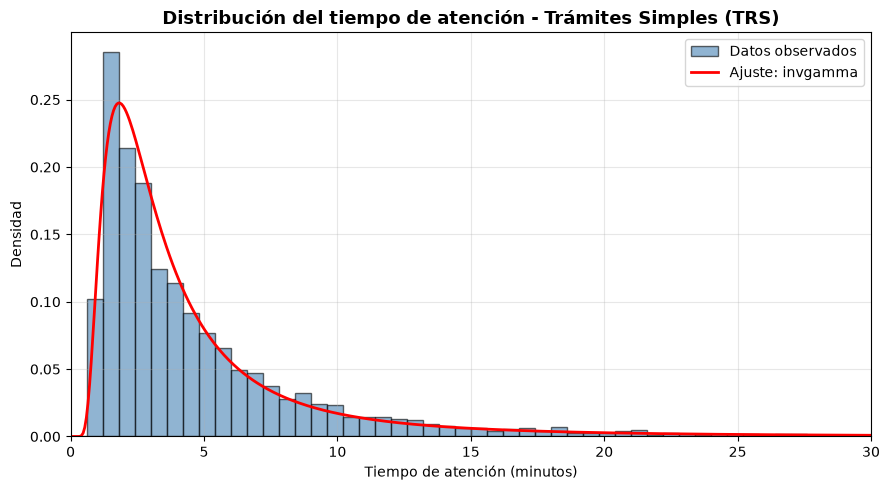

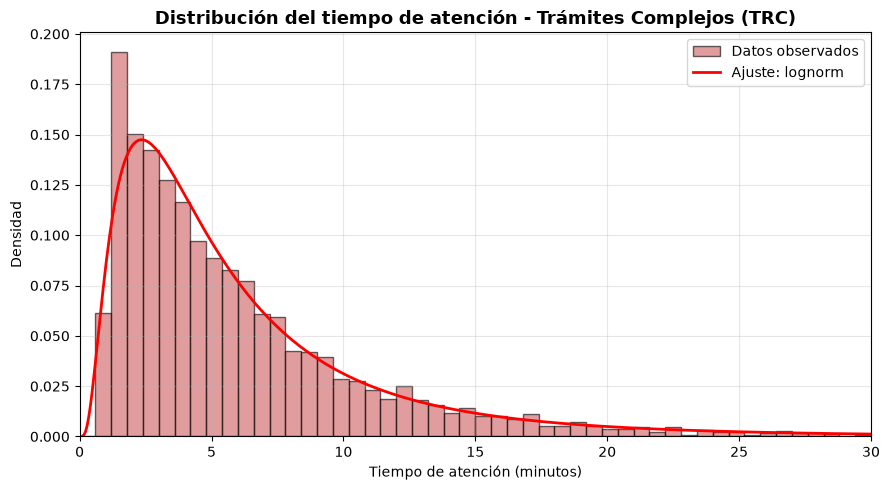

In [ ]:
# 3. Gráficos

def graficar_servicio(datos, info, titulo, color='steelblue', xlim=None, ylim=None, bins=50):
    plt.figure(figsize=(9, 5))
    rango_hist = xlim if xlim else (0, datos.max())
    plt.hist(datos, bins=bins, range=rango_hist, density=True, alpha=0.6,
              color=color, edgecolor='black', label='Datos observados')

    nombre_dist = info['distribucion']
    params = info['params']
    dist = getattr(stats, nombre_dist)

    x_max = xlim[1] if xlim else datos.max()
    x = np.linspace(0.05, x_max, 500)
    y = dist.pdf(x, *params)

    plt.plot(x, y, 'r-', linewidth=2, label=f'Ajuste: {nombre_dist}')
    plt.title(titulo, fontsize=13, fontweight='bold')
    plt.xlabel('Tiempo de atención (minutos)')
    plt.ylabel('Densidad')
    if xlim:
        plt.xlim(xlim)
    if ylim:
        plt.ylim(ylim)
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

graficar_servicio(
    atencion_simple_jit, resultados_servicio['Simple'],
    'Distribución del tiempo de atención - Trámites Simples (TRS)',
    color='steelblue', xlim=(0, 30), bins=50
)

graficar_servicio(
    atencion_compleja_jit, resultados_servicio['Complejo'],
    'Distribución del tiempo de atención - Trámites Complejos (TRC)',
    color='indianred', xlim=(0, 30), bins=50
)

In [ ]:
# 4. Funciones generadoras de tiempo de atención

max_atencion_simple = np.percentile(atencion_simple_jit, 99)
max_atencion_compleja = np.percentile(atencion_compleja_jit, 99)


def _generar_valor_servicio(nombre_dist, params, minimo, maximo):
    dist = getattr(stats, nombre_dist)
    valor = dist.rvs(*params)
    intentos = 0
    while valor <= minimo or valor > maximo:
        valor = dist.rvs(*params)
        intentos += 1
        if intentos > 1000:
            valor = minimo + 1e-3
            break
    return valor

def generar_tiempo_atencion_simple(minimo=0.1, maximo=max_atencion_simple):
    info = resultados_servicio['Simple']
    return _generar_valor_servicio(info['distribucion'], info['params'], minimo, maximo)

def generar_tiempo_atencion_complejo(minimo=0.1, maximo=max_atencion_compleja):
    info = resultados_servicio['Complejo']
    return _generar_valor_servicio(info['distribucion'], info['params'], minimo, maximo)

In [ ]:
print("Simulando 10 tiempos de atención - Trámites Simples:")
for i in range(10):
    print(f"  {i+1}. {generar_tiempo_atencion_simple():.2f} min")

print("Simulando 10 tiempos de atención - Trámites Complejos:")
for i in range(10):
    print(f"  {i+1}. {generar_tiempo_atencion_complejo():.2f} min")

Simulando 10 tiempos de atención - Trámites Simples:
  1. 2.42 min
  2. 2.31 min
  3. 1.06 min
  4. 2.50 min
  5. 1.64 min
  6. 1.81 min
  7. 3.48 min
  8. 12.43 min
  9. 1.88 min
  10. 2.16 min
Simulando 10 tiempos de atención - Trámites Complejos:
  1. 6.52 min
  2. 1.25 min
  3. 6.21 min
  4. 12.67 min
  5. 5.00 min
  6. 8.33 min
  7. 14.13 min
  8. 10.29 min
  9. 9.19 min
  10. 1.04 min


## **Desarrollo del modelo**

In [ ]:
# MOTOR DE SIMULACIÓN

HV = float('inf')

def simular(MA=2, MB=4, N=2, TF_dias=70):

    TF = TF_dias * 24 * 60

    T = 0.0
    TPLLA = T + generar_intervalo_complejo()
    TPLLB = T + generar_intervalo_simple()

    TPSA = [HV] * MA
    TPSB = [HV] * MB
    TPSBC = [HV] * N if N > 0 else []

    ITOA = [T] * MA
    ITOB = [T] * MB
    ITOBC = [T] * N if N > 0 else []

    serv_a_ing = [0.0] * MA
    serv_b_ing = [0.0] * MB
    serv_bc_tipo = ['LIBRE'] * N if N > 0 else []
    serv_bc_ing = [0.0] * N if N > 0 else []

    cola_a = []
    cola_b = []

    NSA = NSB = NSBC = 0
    STIA = STRA = 0.0
    CTRA = CTCRC = 0
    STIB = STRB = 0.0
    CTRB = CTSRC = 0
    STOA = STOB = STOBC = 0.0
    max_cola_a = max_cola_b = 0

    while True:
        min_a = min(TPSA) if TPSA else HV
        idx_a = TPSA.index(min_a) if (TPSA and min_a < HV) else -1
        min_b = min(TPSB) if TPSB else HV
        idx_b = TPSB.index(min_b) if (TPSB and min_b < HV) else -1
        min_bc = min(TPSBC) if TPSBC else HV
        idx_bc = TPSBC.index(min_bc) if (TPSBC and min_bc < HV) else -1

        eventos = [
            (TPLLA, 'LLEGADA_A'), (TPLLB, 'LLEGADA_B'),
            (min_a, 'SALIDA_A'), (min_b, 'SALIDA_B'), (min_bc, 'SALIDA_BC')
        ]
        t_prox, ev = min(eventos, key=lambda x: x[0])
        if t_prox >= HV: break
        T = t_prox

        # LLEGADA trámites COMPLEJOS
        if ev == 'LLEGADA_A':
            TPLLA = T + generar_intervalo_complejo() if T < TF else HV
            if NSA < MA:
                NSA += 1
                pl = TPSA.index(HV)
                TPSA[pl] = T + generar_tiempo_atencion_complejo()
                serv_a_ing[pl] = T
                STOA += (T - ITOA[pl])
            elif N > 0 and NSBC < N:
                NSBC += 1
                pl = TPSBC.index(HV)
                TPSBC[pl] = T + generar_tiempo_atencion_complejo()
                serv_bc_tipo[pl] = 'A'
                serv_bc_ing[pl] = T
                STOBC += (T - ITOBC[pl])
            else:
                NSA += 1
                cola_a.append(T)
                q = NSA - MA
                if q > max_cola_a: max_cola_a = q

        # LLEGADA trámites SIMPLES
        elif ev == 'LLEGADA_B':
            TPLLB = T + generar_intervalo_simple() if T < TF else HV
            if NSB < MB:
                NSB += 1
                pl = TPSB.index(HV)
                TPSB[pl] = T + generar_tiempo_atencion_simple()
                serv_b_ing[pl] = T
                STOB += (T - ITOB[pl])
            elif N > 0 and NSBC < N:
                NSBC += 1
                pl = TPSBC.index(HV)
                TPSBC[pl] = T + generar_tiempo_atencion_simple()
                serv_bc_tipo[pl] = 'B'
                serv_bc_ing[pl] = T
                STOBC += (T - ITOBC[pl])
            else:
                NSB += 1
                cola_b.append(T)
                q = NSB - MB
                if q > max_cola_b: max_cola_b = q

        # SALIDA A
        elif ev == 'SALIDA_A':
            NSA -= 1
            CTRA += 1
            STRA += T
            STIA += serv_a_ing[idx_a]
            if NSA >= MA and cola_a:
                t_sig = cola_a.pop(0)
                TPSA[idx_a] = T + generar_tiempo_atencion_complejo()
                serv_a_ing[idx_a] = t_sig
            else:
                TPSA[idx_a] = HV
                ITOA[idx_a] = T

        # SALIDA B
        elif ev == 'SALIDA_B':
            NSB -= 1
            CTRB += 1
            STRB += T
            STIB += serv_b_ing[idx_b]
            if NSB >= MB and cola_b:
                t_sig = cola_b.pop(0)
                TPSB[idx_b] = T + generar_tiempo_atencion_simple()
                serv_b_ing[idx_b] = t_sig
            else:
                TPSB[idx_b] = HV
                ITOB[idx_b] = T

        # SALIDA DE EVALUADORES
        elif ev == 'SALIDA_BC':
            tipo_fin = serv_bc_tipo[idx_bc]
            t_ing = serv_bc_ing[idx_bc]
            if tipo_fin == 'A':
                CTCRC += 1
                STRA += T
                STIA += t_ing
            elif tipo_fin == 'B':
                CTSRC += 1
                STRB += T
                STIB += t_ing

            NSBC -= 1
            if NSA > MA and cola_a:
                t_sig = cola_a.pop(0)
                NSA -= 1
                NSBC += 1
                TPSBC[idx_bc] = T + generar_tiempo_atencion_complejo()
                serv_bc_tipo[idx_bc] = 'A'
                serv_bc_ing[idx_bc] = t_sig
            elif NSB > MB and cola_b:
                t_sig = cola_b.pop(0)
                NSB -= 1
                NSBC += 1
                TPSBC[idx_bc] = T + generar_tiempo_atencion_simple()
                serv_bc_tipo[idx_bc] = 'B'
                serv_bc_ing[idx_bc] = t_sig
            else:
                TPSBC[idx_bc] = HV
                serv_bc_tipo[idx_bc] = 'LIBRE'
                ITOBC[idx_bc] = T

        # VACIAMIENTO
        if T >= TF:
            TPLLA = HV
            TPLLB = HV
            if (NSA + NSB + NSBC) == 0:
                break

    for i in range(MA):
        if TPSA[i] >= HV: STOA += (T - ITOA[i])
    for i in range(MB):
        if TPSB[i] >= HV: STOB += (T - ITOB[i])

    total_a = CTRA
    total_b = CTRB

    tppa = ((STRA - STIA) / total_a) if total_a > 0 else 0.0
    tppb = ((STRB - STIB) / total_b) if total_b > 0 else 0.0
    ptc = (CTCRC / total_a * 100.0) if total_a > 0 else 0.0
    pts = (CTSRC / total_b * 100.0) if total_b > 0 else 0.0
    ptoa = (STOA / (T * MA) * 100.0) if (T * MA) > 0 else 0.0
    ptob = (STOB / (T * MB) * 100.0) if (T * MB) > 0 else 0.0

    return {
        'N': N, 'MA': MA, 'MB': MB,
        'TPPA': round(tppa, 2), 'TPPB': round(tppb, 2),
        'Suma_TPP': round(tppa + tppb, 2),
        'PTC': round(ptc, 2), 'PTS': round(pts, 2),
        'PTOA': round(ptoa, 2), 'PTOB': round(ptob, 2),
        'Total_A': total_a, 'Total_B': total_b,
        'Max_Cola_A': max_cola_a, 'Max_Cola_B': max_cola_b,
        'T_final_dias': round(T / (24 * 60), 1)
    }

Resultados comparativos:


,TPPA,TPPB,PTC,PTS,PTOA,PTOB
N,,,,,,
0,6.39,4.87,0.00,0.00,91.28,80.76
2,6.52,4.95,4.28,7.67,91.17,82.58
4,6.51,5.00,4.34,9.06,90.83,82.48


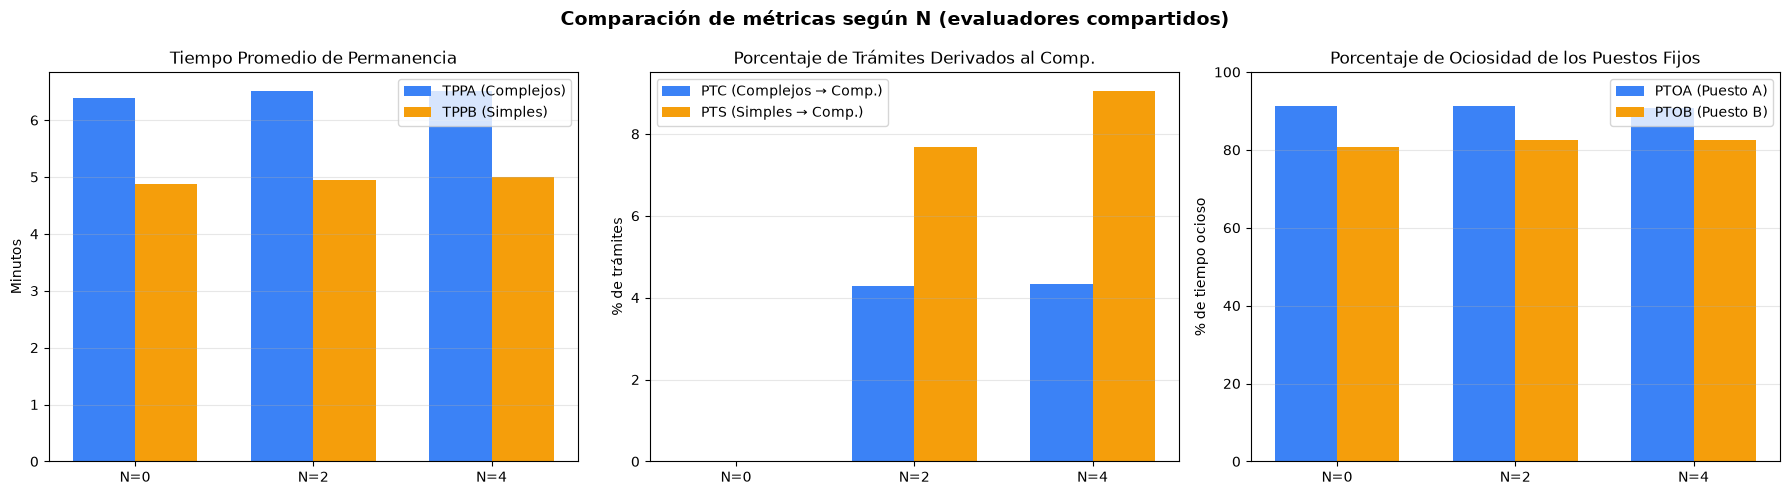

In [ ]:
  # COMPARACIÓN GRÁFICA DE ESCENARIOS (N=0, N=2, N=4)

MA = 2
MB = 4
TF_DIAS = 70

escenarios_n = [0, 2, 4]
resultados_comparacion = []

for n in escenarios_n:
    res = simular(MA=MA, MB=MB, N=n, TF_dias=TF_DIAS)
    resultados_comparacion.append(res)

df_comp = pd.DataFrame(resultados_comparacion)
df_comp = df_comp.set_index('N')

print("Resultados comparativos:")
display(df_comp[['TPPA', 'TPPB', 'PTC', 'PTS', 'PTOA', 'PTOB']].style.format(precision=2))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Comparación de métricas según N (evaluadores compartidos)', fontsize=14, fontweight='bold')

x = np.arange(len(escenarios_n))
width = 0.35

# Gráfico 1: Tiempos promedio de permanencia (TPPA vs TPPB)
ax1 = axes[0]
ax1.bar(x - width/2, df_comp['TPPA'], width, label='TPPA (Complejos)', color='#3b82f6')
ax1.bar(x + width/2, df_comp['TPPB'], width, label='TPPB (Simples)', color='#f59e0b')
ax1.set_xticks(x)
ax1.set_xticklabels([f'N={n}' for n in escenarios_n])
ax1.set_ylabel('Minutos')
ax1.set_title('Tiempo Promedio de Permanencia')
ax1.legend()
ax1.grid(axis='y', alpha=0.3)

# Gráfico 2: % de trámites derivados a los evaluadores compartido (PTC vs PTS)
ax2 = axes[1]
ax2.bar(x - width/2, df_comp['PTC'], width, label='PTC (Complejos → Comp.)', color='#3b82f6')
ax2.bar(x + width/2, df_comp['PTS'], width, label='PTS (Simples → Comp.)', color='#f59e0b')
ax2.set_xticks(x)
ax2.set_xticklabels([f'N={n}' for n in escenarios_n])
ax2.set_ylabel('% de trámites')
ax2.set_title('Porcentaje de Trámites Derivados al Comp.')
ax2.legend()
ax2.grid(axis='y', alpha=0.3)

# Gráfico 3: Ociosidad de puestos (PTOA vs PTOB)
ax3 = axes[2]
ax3.bar(x - width/2, df_comp['PTOA'], width, label='PTOA (Puesto A)', color='#3b82f6')
ax3.bar(x + width/2, df_comp['PTOB'], width, label='PTOB (Puesto B)', color='#f59e0b')
ax3.set_xticks(x)
ax3.set_xticklabels([f'N={n}' for n in escenarios_n])
ax3.set_ylabel('% de tiempo ocioso')
ax3.set_title('Porcentaje de Ociosidad de los Puestos Fijos')
ax3.set_ylim(0, 100)
ax3.legend()
ax3.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()